In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_curve, auc)
from sklearn.pipeline import Pipeline
import string
import re
import warnings
warnings.filterwarnings('ignore')

In [2]:
print("=" * 60)
print("EMAIL SPAM DETECTION WITH MACHINE LEARNING")
print("=" * 60)

EMAIL SPAM DETECTION WITH MACHINE LEARNING


In [5]:
df = pd.read_csv('spam.csv', encoding='latin-1')
df = df[['v1', 'v2']]
df.columns = ['label', 'message']

In [8]:
print(f"\nDataset Shape: {df.shape}")
print(f"\nFirst 5 rows:")
print(df.head())
print(f"\nLabel Distribution:")
print(df['label'].value_counts())



Dataset Shape: (5572, 2)

First 5 rows:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Label Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [9]:
print("\n" + "=" * 60)
print("DATA EXPLORATION")
print("=" * 60)

df['message_length'] = df['message'].apply(len)
df['word_count'] = df['message'].apply(lambda x: len(x.split()))

print(f"\nAverage message length:")
print(df.groupby('label')['message_length'].mean())

print(f"\nAverage word count:")
print(df.groupby('label')['word_count'].mean())


DATA EXPLORATION

Average message length:
label
ham      71.023627
spam    138.866131
Name: message_length, dtype: float64

Average word count:
label
ham     14.200622
spam    23.851406
Name: word_count, dtype: float64


In [13]:
print("\n" + "=" * 60)
print("TEXT PREPROCESSING")
print("=" * 60)

def preprocess_text(text):
    """Clean and preprocess email/SMS text."""
    # Lowercase
    text = text.lower()
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Remove numbers
    text = re.sub(r'\d+', '', text)
    # Remove extra whitespace
    text = text.strip()
    return text

df['cleaned_message'] = df['message'].apply(preprocess_text)

print("\nSample cleaned messages:")
print(df[['message', 'cleaned_message']].head(3))

# Encode labels
df['label_encoded'] = df['label'].map({'ham': 0, 'spam': 1})

# ─────────────────────────────────────────────
# 4. TRAIN-TEST SPLIT
# ─────────────────────────────────────────────
X = df['cleaned_message']
y = df['label_encoded']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTraining samples: {len(X_train)}")
print(f"Testing samples:  {len(X_test)}")



TEXT PREPROCESSING

Sample cleaned messages:
                                             message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   

                                     cleaned_message  
0  go until jurong point crazy available only in ...  
1                            ok lar joking wif u oni  
2  free entry in  a wkly comp to win fa cup final...  

Training samples: 4457
Testing samples:  1115


In [14]:
print("\n" + "=" * 60)
print("MODEL TRAINING & EVALUATION")
print("=" * 60)

models = {
    'Naive Bayes': Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', max_features=5000)),
        ('clf', MultinomialNB())
    ]),
    'Logistic Regression': Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', max_features=5000)),
        ('clf', LogisticRegression(max_iter=1000))
    ]),
    'Random Forest': Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', max_features=5000)),
        ('clf', RandomForestClassifier(n_estimators=100, random_state=42))
    ]),
    'SVM': Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', max_features=5000)),
        ('clf', SVC(kernel='linear', probability=True))
    ])
}

results = {}
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = {'accuracy': acc, 'model': pipeline, 'y_pred': y_pred}
    print(f"\n{name}: Accuracy = {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))



MODEL TRAINING & EVALUATION

Naive Bayes: Accuracy = 0.9659
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       0.99      0.75      0.85       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115


Logistic Regression: Accuracy = 0.9632
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       0.99      0.73      0.84       149

    accuracy                           0.96      1115
   macro avg       0.98      0.87      0.91      1115
weighted avg       0.96      0.96      0.96      1115


Random Forest: Accuracy = 0.9758
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.99       966
        Spam       0.99      0.83      0.90       149

    accuracy                           0.98    


GENERATING VISUALIZATIONS


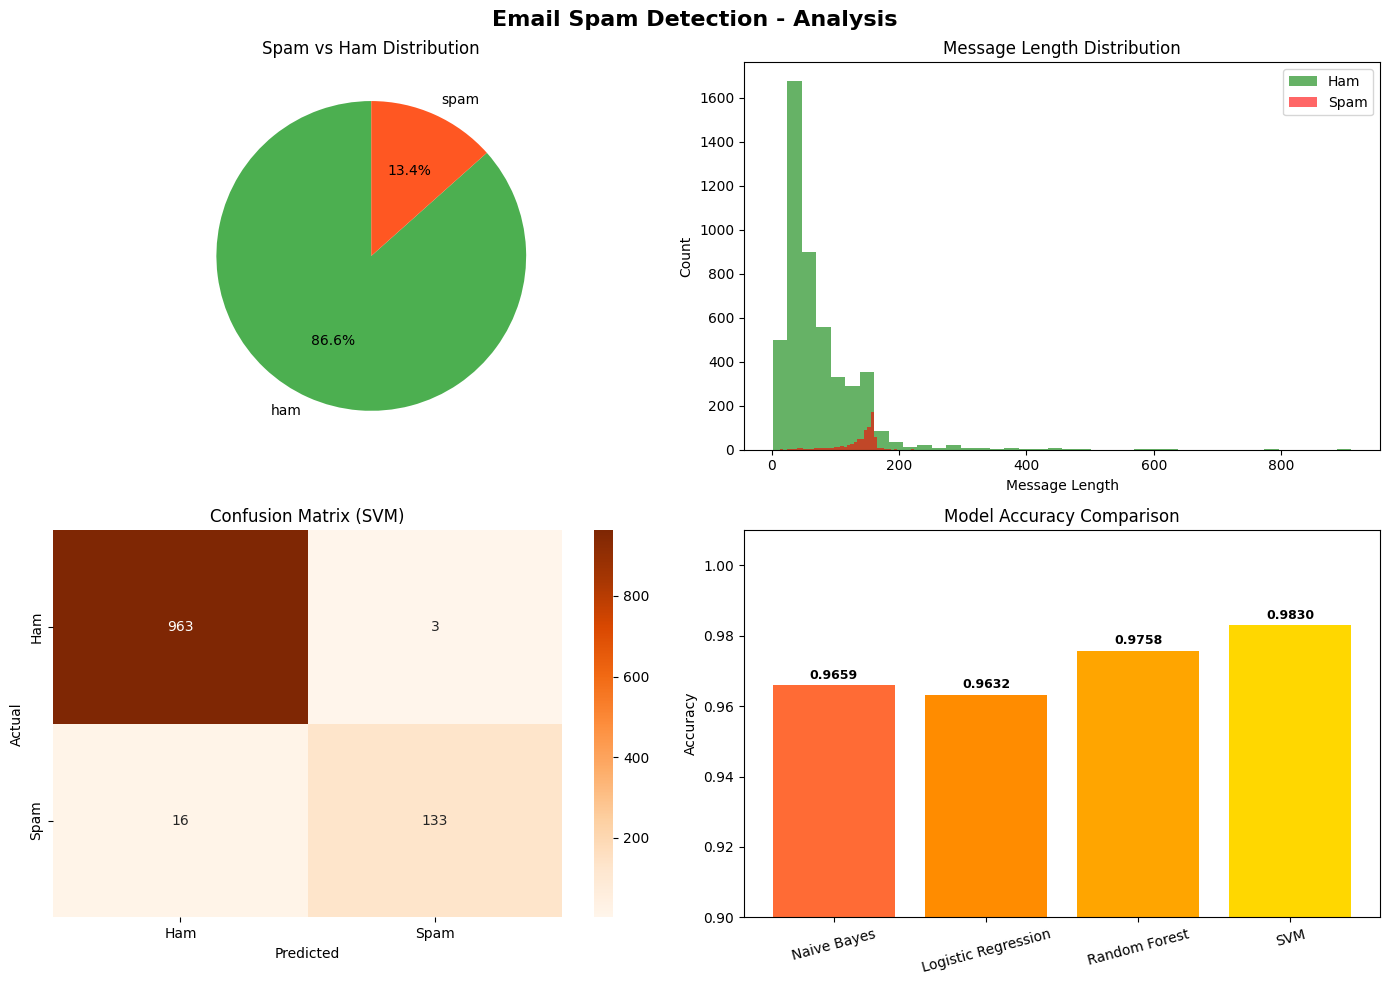


Visualization saved as 'spam_detection_results.png'


In [16]:
print("\n" + "=" * 60)
print("GENERATING VISUALIZATIONS")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Email Spam Detection - Analysis', fontsize=16, fontweight='bold')

# Plot 1: Spam vs Ham distribution
labels_count = df['label'].value_counts()
axes[0, 0].pie(labels_count, labels=labels_count.index, autopct='%1.1f%%',
               colors=['#4CAF50', '#FF5722'], startangle=90)
axes[0, 0].set_title('Spam vs Ham Distribution')

# Plot 2: Message length comparison
spam_len = df[df['label'] == 'spam']['message_length']
ham_len = df[df['label'] == 'ham']['message_length']
axes[0, 1].hist(ham_len, bins=40, alpha=0.6, color='green', label='Ham')
axes[0, 1].hist(spam_len, bins=40, alpha=0.6, color='red', label='Spam')
axes[0, 1].set_title('Message Length Distribution')
axes[0, 1].set_xlabel('Message Length')
axes[0, 1].set_ylabel('Count')
axes[0, 1].legend()

# Plot 3: Confusion Matrix (Best model - SVM or Logistic Regression)
best_model_name = max(results, key=lambda x: results[x]['accuracy'])
best_y_pred = results[best_model_name]['y_pred']
cm = confusion_matrix(y_test, best_y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[1, 0],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[1, 0].set_title(f'Confusion Matrix ({best_model_name})')
axes[1, 0].set_ylabel('Actual')
axes[1, 0].set_xlabel('Predicted')

# Plot 4: Model Accuracy Comparison
model_names = list(results.keys())
accuracies = [results[m]['accuracy'] for m in model_names]
bars = axes[1, 1].bar(model_names, accuracies, color=['#FF6B35', '#FF8C00', '#FFA500', '#FFD700'])
axes[1, 1].set_title('Model Accuracy Comparison')
axes[1, 1].set_ylabel('Accuracy')
axes[1, 1].set_ylim(0.9, 1.01)
axes[1, 1].tick_params(axis='x', rotation=15)
for bar, acc in zip(bars, accuracies):
    axes[1, 1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.001,
                    f'{acc:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('spam_detection_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nVisualization saved as 'spam_detection_results.png'")

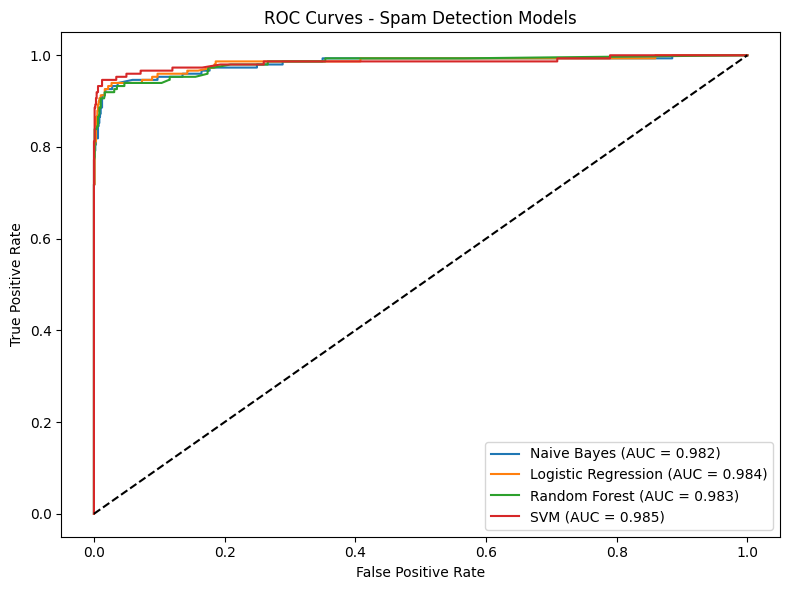

ROC curves saved as 'roc_curves.png'

PREDICT NEW MESSAGES

Using Best Model: SVM

Message: Congratulations! You've won a $1000 gift card. Click here to...
Prediction: 🚨 SPAM | Confidence: 99.55%

Message: Hey, are we still meeting for lunch tomorrow?...
Prediction: ✅ HAM | Confidence: 99.99%

Message: URGENT: Your account has been compromised. Call us immediate...
Prediction: 🚨 SPAM | Confidence: 99.47%

Message: Can you send me the report by end of day please?...
Prediction: ✅ HAM | Confidence: 94.92%



In [18]:
plt.figure(figsize=(8, 6))
for name, res in results.items():
    y_prob = res['model'].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Spam Detection Models')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("ROC curves saved as 'roc_curves.png'")

# ─────────────────────────────────────────────
# 8. PREDICT NEW MESSAGES
# ─────────────────────────────────────────────
print("\n" + "=" * 60)
print("PREDICT NEW MESSAGES")
print("=" * 60)

best_pipeline = results[best_model_name]['model']

test_messages = [
    "Congratulations! You've won a $1000 gift card. Click here to claim now!",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT: Your account has been compromised. Call us immediately at 1-800-SPAM",
    "Can you send me the report by end of day please?"
]

print(f"\nUsing Best Model: {best_model_name}\n")
for msg in test_messages:
    cleaned = preprocess_text(msg)
    prediction = best_pipeline.predict([cleaned])[0]
    prob = best_pipeline.predict_proba([cleaned])[0]
    label = "🚨 SPAM" if prediction == 1 else "✅ HAM"
    print(f"Message: {msg[:60]}...")
    print(f"Prediction: {label} | Confidence: {max(prob):.2%}\n")
